# Alerte gel : de l'erreur de prédiction à la décision

Ce notebook reprend les résultats de la chaine de traitement et montre, en
quelques étapes, le raisonnement qui mène du modèle à la règle d'alerte. Il ne
réentraine rien : il repart des prédictions de test écrites par la chaine.

Prérequis : avoir exécuté `python -m gel tout` une fois, ce qui produit
`data/processed/predictions_test.parquet`.

Le détail complet est dans [le rapport de résultats](../rapports/resultats.md),
la lecture métier dans [la note de décision](../rapports/note_de_decision.md), et
la critique du rendu d'origine dans
[la revue de la version initiale](../rapports/revue_de_la_version_initiale.md).

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "src"))

from gel.config import charger_config
from gel.features import pression_vapeur_saturante
from gel.io import lire_parquet
from gel.metrics import (
    agreger_par_nuit,
    balayage_seuil_alerte,
    matrice_gel,
    metriques_par_groupe,
    tableau_metriques,
)
from gel import viz

cfg = charger_config(Path.cwd().parent / "config" / "config.toml")
predictions = lire_parquet(cfg.chemin("predictions"))

MODELES = [
    "Stull (coefficients publiés)",
    "Stull recalibré",
    "Régression polynomiale",
    "Gradient boosting",
]
CIBLE = cfg.cible

print(f"{len(predictions):,} heures de test".replace(",", " "))
print(f"du {predictions['date'].min():%d/%m/%Y} au {predictions['date'].max():%d/%m/%Y}")
print(f"{predictions['station_id'].nunique()} stations")
predictions.head(3)

291 431 heures de test
du 15/03/2023 au 31/05/2023
1409 stations


,station_id,fin_fenetre,date,mois,hour,T2M,T2M_U_med,Persistance 2 m,Stull (coefficients publiés),Stull recalibré,Régression polynomiale,Gradient boosting
0,4124,2023-03-15 01:00:00,2023-03-15,3,1,8.4,8.6,8.4,4.886334,6.059128,6.127762,6.106169
1,4126,2023-03-15 01:00:00,2023-03-15,3,1,7.8,7.6,7.8,4.530098,5.581016,5.746146,5.590049
2,4127,2023-03-15 01:00:00,2023-03-15,3,1,8.9,8.6,8.9,6.338040,6.909910,7.171260,7.245356


## 1. L'erreur en degrés

Premier niveau de lecture, celui de l'équipe technique. Les trois approches
demandées par l'énoncé se tiennent dans deux centièmes de degré : le gradient
boosting à dix-sept variables ne bat pas une formule physique à cinq paramètres.

In [2]:
resume = pd.DataFrame(
    [
        {"modèle": nom, **tableau_metriques(predictions[CIBLE], predictions[nom])}
        for nom in MODELES
    ]
)
resume[
    ["modèle", "rmse", "mae", "biais", "depassement_1C_pct", "depassement_2C_pct", "r2"]
].round(3)

,modèle,rmse,mae,biais,depassement_1C_pct,depassement_2C_pct,r2
0,Stull (coefficients publiés),1.402,1.067,0.055,42.022,15.297,0.726
1,Stull recalibré,1.208,0.948,-0.035,38.837,10.675,0.796
2,Régression polynomiale,1.213,0.950,-0.065,39.031,10.749,0.795
3,Gradient boosting,1.218,0.953,-0.064,39.181,10.889,0.793


La RMSE de 1,21 °C ne dit pas tout : l'erreur dépasse 1 °C dans près de 40 %
des heures. Le biais, lui, est signé, et c'est le chiffre à surveiller. Un modèle
qui surestime la température humide sous-estime le risque de gel, ce qui est la
seule erreur réellement couteuse.

## 2. Pourquoi les trois approches plafonnent au même niveau

L'explication est dans les données, pas dans les modèles. Sur les dix variables
autorisées, l'humidité relative, le point de rosée et le déficit de pression
saturante décrivent la même quantité physique. Vérification directe : on
recalcule l'humidité relative à partir de la température et du point de rosée,
avec la formule de Tetens, et on la compare à la colonne fournie.

In [3]:
propre = lire_parquet(
    cfg.chemin("clean_parquet"), colonnes=["T2M", "DEWT2M", "RH2M", "VPD"]
).sample(200_000, random_state=cfg.graine)

humidite_recalculee = (
    100 * pression_vapeur_saturante(propre["DEWT2M"]) / pression_vapeur_saturante(propre["T2M"])
)
vpd_recalcule = pression_vapeur_saturante(propre["T2M"]) - pression_vapeur_saturante(
    propre["DEWT2M"]
)

print("écart sur l'humidité relative (points de pourcentage)")
print(pd.Series(humidite_recalculee - propre["RH2M"]).abs().quantile([0.5, 0.95, 0.99]).round(2))
print("\nécart sur le déficit de pression saturante (kPa)")
print(pd.Series(vpd_recalcule - propre["VPD"]).abs().quantile([0.5, 0.95, 0.99]).round(3))

écart sur l'humidité relative (points de pourcentage)
0.50    0.29
0.95    0.58
0.99    0.65
Name: RH2M, dtype: float64

écart sur le déficit de pression saturante (kPa)


0.50    0.003
0.95    0.009
0.99    0.011
Name: VPD, dtype: float64


Trois des dix variables disent donc la même chose. Ajouter de la capacité au
modèle ne crée pas d'information : c'est ce que montre la grille de sélection du
gradient boosting, dont les trois configurations se tiennent dans un centième de
degré.

## 3. L'erreur n'est pas uniforme, et elle est la plus forte là où elle compte

In [4]:
detail = predictions[[CIBLE] + MODELES].copy()
detail["regime"] = pd.cut(
    detail[CIBLE],
    bins=[-np.inf, -3, -1, 0, 2, 5, np.inf],
    labels=["< -3", "-3 à -1", "-1 à 0", "0 à 2", "2 à 5", "> 5"],
)

par_regime = pd.concat(
    [
        metriques_par_groupe(
            detail.assign(prediction=detail[nom]), "regime", CIBLE, "prediction"
        ).assign(modèle=nom)
        for nom in MODELES
    ]
)
par_regime.pivot_table(index="regime", columns="modèle", values="rmse", observed=True).round(3)

modèle,Gradient boosting,Régression polynomiale,Stull (coefficients publiés),Stull recalibré
regime,,,,
< -3,1.608,1.620,1.995,1.604
-3 à -1,1.455,1.451,1.638,1.462
-1 à 0,1.385,1.376,1.544,1.424
0 à 2,1.475,1.468,1.685,1.511
2 à 5,1.348,1.340,1.478,1.337
> 5,1.117,1.113,1.323,1.098


La RMSE moyenne est tirée vers le bas par les nuits douces, qui sont les plus
nombreuses. Dans le froid, c'est-à-dire dans les situations qui déclenchent une
alerte, l'erreur est nettement plus élevée. Annoncer « 1,2 °C de précision » sans
cette nuance serait trompeur.

## 4. De l'erreur à la décision : la maille de la nuit

Une gelée est un évènement nocturne. Compter les erreurs à l'heure multiplie les
pertes par la durée de l'épisode, alors qu'une nuit de gel de six heures ne
détruit la récolte qu'une fois et ne déclenche le dispositif antigel qu'une
fois. On agrège donc par station et par nuit, en gardant le minimum, qui est la
grandeur de décision.

In [5]:
evenements = {
    nom: agreger_par_nuit(
        predictions[["station_id", "fin_fenetre", CIBLE]].assign(prediction=predictions[nom]),
        colonne_cible=CIBLE,
    )
    for nom in MODELES
}

contingences = {
    nom: matrice_gel(table["minimum_mesure"], table["minimum_prediction"], 0.0)
    for nom, table in evenements.items()
}

table_nuit = pd.DataFrame(contingences).T[
    ["pod_rappel", "far_fausses_alertes", "csi", "vrais_positifs", "faux_negatifs", "faux_positifs"]
]
table_nuit[["pod_rappel", "far_fausses_alertes"]] *= 100
table_nuit.round(1)

,pod_rappel,far_fausses_alertes,csi,vrais_positifs,faux_negatifs,faux_positifs
Stull (coefficients publiés),56.4,17.1,0.5,1644.0,1269.0,340.0
Stull recalibré,66.9,18.7,0.6,1949.0,964.0,449.0
Régression polynomiale,70.7,20.3,0.6,2059.0,854.0,523.0
Gradient boosting,70.4,20.0,0.6,2050.0,863.0,514.0


Le classement change par rapport à la RMSE : la régression polynomiale, dont
l'erreur moyenne est légèrement moins bonne que celle de la formule recalibrée,
détecte une centaine de nuits de gel de plus. La raison tient à la structure du
problème : la RMSE se joue sur les nuits douces, la détection sur la queue
froide.

## 5. Le vrai levier : le seuil d'alerte

Rater une gelée coute une récolte. Alerter pour rien coute une nuit de
mobilisation. Le rapport entre les deux, ici 33, décide du seuil. Il n'y a aucune
raison pour qu'il tombe sur 0 °C.

In [6]:
seuils = np.round(np.arange(-1.0, 3.01, 0.1), 2)
balayages = {
    nom: balayage_seuil_alerte(
        table["minimum_mesure"].to_numpy(),
        table["minimum_prediction"].to_numpy(),
        seuils,
        cfg.metier["cout_gelee_non_detectee_eur_ha"],
        cfg.metier["cout_fausse_alerte_eur_ha"],
        0.0,
        cfg.metier["surface_suivie_ha"],
    )
    for nom, table in evenements.items()
}

for nom, table in balayages.items():
    optimum = table.loc[table["cout_total_eur"].idxmin()]
    reference = table.loc[np.isclose(table["seuil_alerte"], 0.0)].iloc[0]
    print(
        f"{nom:30s} seuil optimal {optimum['seuil_alerte']:+.1f} °C  "
        f"détection {100 * optimum['pod_rappel']:.1f} %  "
        f"cout divisé par {reference['cout_total_eur'] / optimum['cout_total_eur']:.1f}"
    )

Stull (coefficients publiés)   seuil optimal +2.5 °C  détection 96.7 %  cout divisé par 6.1
Stull recalibré                seuil optimal +2.6 °C  détection 98.6 %  cout divisé par 5.4
Régression polynomiale         seuil optimal +2.5 °C  détection 98.9 %  cout divisé par 4.8
Gradient boosting              seuil optimal +2.3 °C  détection 98.2 %  cout divisé par 4.8


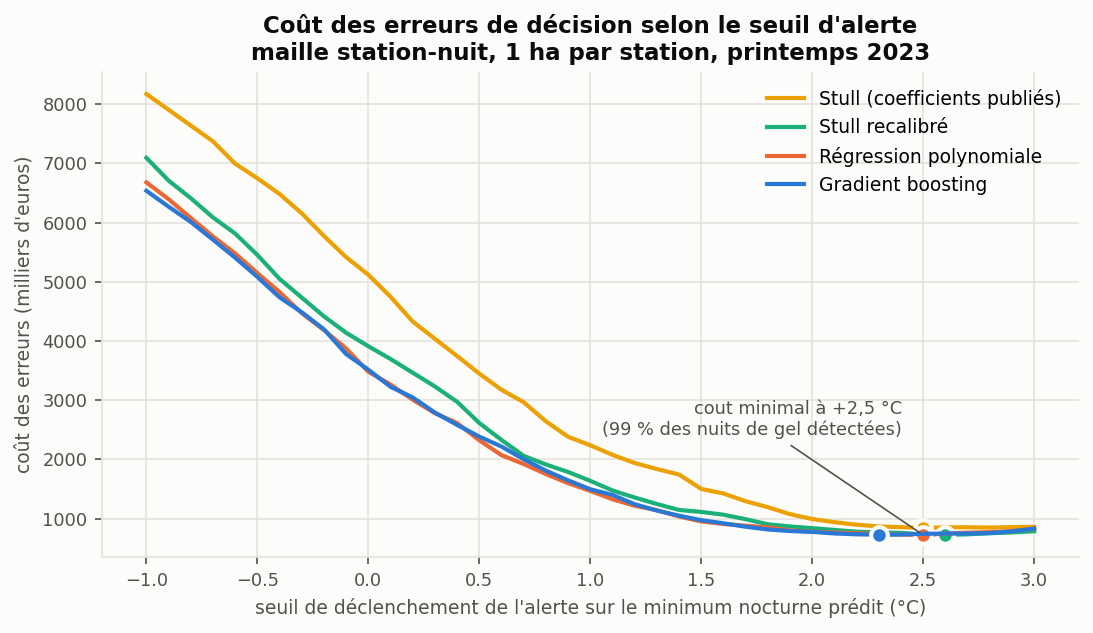

In [7]:
chemin = Path.cwd().parent / "rapports" / "figures" / "cout_par_seuil.png"
viz.figure_cout_par_seuil(balayages, chemin, cfg.metier["surface_suivie_ha"])

from IPython.display import Image

Image(str(chemin))

## Ce qu'il faut retenir

1. Les trois approches sont équivalentes à deux centièmes de degré près. Le
   choix se fait donc sur le cout d'exploitation, et il va à la formule
   recalibrée : quatre coefficients, aucune dépendance, vérifiable à la main.
2. Le modèle le plus précis au sens de la RMSE n'est pas celui qui détecte le
   mieux le gel. Choisir sur une métrique de régression seule serait une erreur.
3. Le gain le plus important ne vient pas du modèle mais du seuil d'alerte :
   passer de 0 °C à +2,5 °C divise le cout des erreurs par cinq et porte la
   détection à 99 %. C'est une décision de produit, à prendre avec l'exploitant.